# 📊 Notebook Kiểm Thử Pipeline: `data_processing` & `dataloader`
Notebook này được thiết kế để kiểm thử toàn diện quy trình xử lý dữ liệu và nạp dữ liệu cho mô hình **Adaptive_SupConST_DIC**:
1. **Kiểm thử `data_processing`**:
   - Hàm đọc ảnh `read_image` / `read_image_as_tensor`
   - Các biến đổi tăng cường dữ liệu: `RandomShear`, `RandomBrightness`, `RandomErase`, `GaussianNoise`, `get_transforms`
   - Lớp `RVLCDIPDataset` (hỗ trợ cả Single-view và Two-Crop Contrastive Views)
   - Lớp gom lô `LayoutLMv3DataCollator` (tích hợp LayoutLMv3 Image Processor)
2. **Kiểm thử `dataloader` (`utils/dataloader.py`)**:
   - `build_dataset`: Hàm tiện ích khởi tạo dataset
   - `build_dataloader`: Khởi tạo DataLoader cho 1 split (train/val/test)
   - `get_dataloaders`: Khởi tạo đồng bộ cả 3 split (train, val, test)
3. **Trực quan hóa (Visualization)**:
   - Hiển thị so sánh ảnh gốc và các góc nhìn (views) tăng cường
   - Trực quan hóa trọn vẹn 1 batch Contrastive (View 1 vs View 2) kèm nhãn tài liệu tương ứng.


In [1]:
import os
import sys
from pathlib import Path
import torch
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoProcessor

# Thêm root directory vào sys.path nếu cần
project_root = Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Import từ module data_processing
from data_processing.data_processing import (
    read_image,
    read_image_as_tensor,
    RandomShear,
    RandomBrightness,
    RandomErase,
    GaussianNoise,
    TwoCropTransform,
    get_transforms,
    RVLCDIPDataset,
    LayoutLMv3DataCollator,
)

# Import từ module utils.dataloader
from utils.dataloader import (
    build_dataset,
    build_dataloader,
    get_dataloaders,
)

print("✅ Đã import thành công tất cả module từ data_processing và utils.dataloader!")
print(f"📦 PyTorch version: {torch.__version__} | CUDA available: {torch.cuda.is_available()}")


✅ Đã import thành công tất cả module từ data_processing và utils.dataloader!
📦 PyTorch version: 2.14.1+cpu | CUDA available: False


In [2]:
def to_displayable(tensor: torch.Tensor) -> np.ndarray:
    """
    Chuyển đổi tensor ảnh sang mảng numpy (H, W, C) với giá trị [0.0, 1.0]
    để hiển thị chuẩn xác bằng matplotlib.
    """
    t = tensor.detach().cpu().float().clone()
    if t.ndim == 3 and t.shape[0] in (1, 3):
        # Kiểm tra nếu tensor đã qua LayoutLMv3 processor chuẩn hóa về khoảng [-1, 1]
        if t.min() < 0.0:
            t = (t * 0.5 + 0.5).clamp(0.0, 1.0)
        elif t.max() > 1.0:
            # Tensor uint8 [0, 255]
            t = (t / 255.0).clamp(0.0, 1.0)
        return t.permute(1, 2, 0).numpy()
    return t.numpy()

print("✅ Đã định nghĩa hàm hỗ trợ hiển thị to_displayable.")


✅ Đã định nghĩa hàm hỗ trợ hiển thị to_displayable.


## 1. Kiểm thử Đọc ảnh & Augmentation (`data_processing`)
Đọc 1 ảnh thực tế từ dataset RVL-CDIP, áp dụng chuỗi biến đổi tăng cường dữ liệu (`get_transforms`) và sinh ra 2 views cho Contrastive Learning.


Đường dẫn ảnh mẫu: dataset\rvl-cdip\images\imagesq\q\o\c\qoc54c00\80035521.tif
Tồn tại: True | Nhãn ID: 15 (memo)
Shape ảnh gốc: torch.Size([3, 1000, 754]) | Dtype: torch.uint8 | Range: [0, 255]


View 1 shape: torch.Size([3, 1000, 754]) | View 2 shape: torch.Size([3, 1000, 754])


Mức độ sai khác trung bình giữa 2 views: 14.0048 (Augmentation hoạt động tốt)


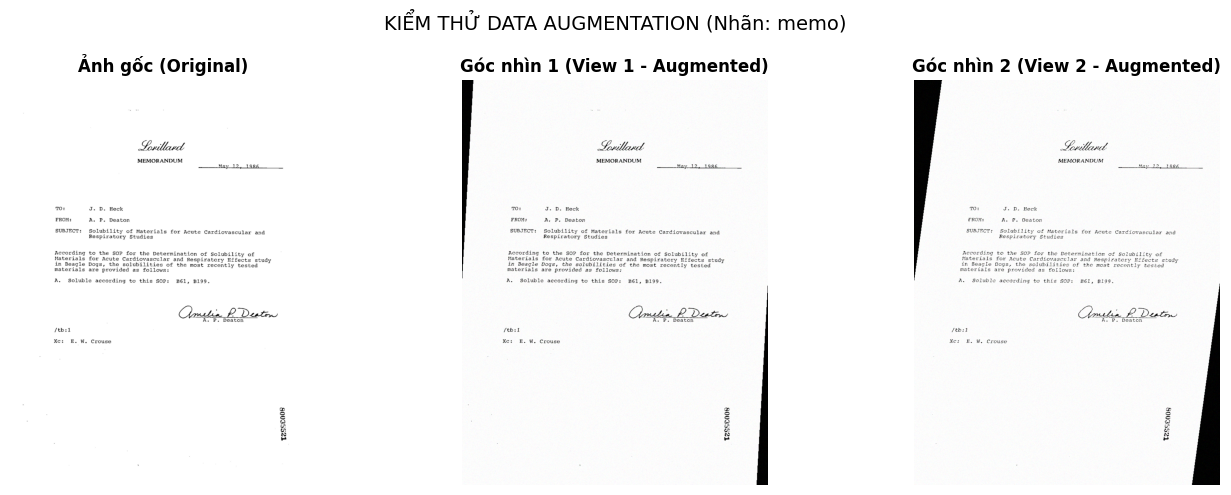

In [3]:
# 1. Tìm đường dẫn 1 ảnh mẫu từ file nhãn
data_dir = Path("dataset/rvl-cdip")
label_file = data_dir / "labels" / "train.txt"

assert label_file.exists(), f"Không tìm thấy file nhãn tại {label_file}"

with open(label_file, "r", encoding="utf-8") as f:
    sample_rel_path, sample_label = f.readline().strip().split()

sample_img_path = data_dir / "images" / sample_rel_path
print(f"Đường dẫn ảnh mẫu: {sample_img_path}")
print(f"Tồn tại: {sample_img_path.exists()} | Nhãn ID: {sample_label} ({RVLCDIPDataset.LABEL_NAMES[int(sample_label)]})")

# 2. Đọc ảnh thành Tensor gốc
img_tensor = read_image_as_tensor(sample_img_path)
print(f"Shape ảnh gốc: {img_tensor.shape} | Dtype: {img_tensor.dtype} | Range: [{img_tensor.min()}, {img_tensor.max()}]")

# 3. Khởi tạo Augmentation pipeline
augment = get_transforms(
    max_shear=12.0,
    brightness_range=(0.7, 1.3),
    noise_std=6.0,
    p_erase=0.4,
)

# 4. Sinh 2 góc nhìn (2 views) khác nhau từ cùng 1 ảnh
view1 = augment(img_tensor)
view2 = augment(img_tensor)

diff = torch.abs(view1.float() - view2.float()).mean().item()
print(f"View 1 shape: {view1.shape} | View 2 shape: {view2.shape}")
print(f"Mức độ sai khác trung bình giữa 2 views: {diff:.4f} (Augmentation hoạt động tốt)")

# 5. Trực quan hóa
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(to_displayable(img_tensor))
axes[0].set_title("Ảnh gốc (Original)", fontsize=12, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(to_displayable(view1))
axes[1].set_title("Góc nhìn 1 (View 1 - Augmented)", fontsize=12, fontweight="bold")
axes[1].axis("off")

axes[2].imshow(to_displayable(view2))
axes[2].set_title("Góc nhìn 2 (View 2 - Augmented)", fontsize=12, fontweight="bold")
axes[2].axis("off")

plt.suptitle(f"KIỂM THỬ DATA AUGMENTATION (Nhãn: {RVLCDIPDataset.LABEL_NAMES[int(sample_label)]})", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()


## 2. Kiểm thử Lớp `RVLCDIPDataset`
Kiểm tra cả 2 chế độ:
- Chế độ đơn góc nhìn (`is_contrastive=False`)
- Chế độ học tương phản 2 góc nhìn (`is_contrastive=True`)


In [4]:
# 1. Dataset chế độ Single-view
ds_single = build_dataset(
    root=data_dir,
    split="train",
    transform=None,
    is_contrastive=False,
    max_samples=20,
)
print(f"✅ ds_single số mẫu: {len(ds_single)}")
item_single = ds_single[0]
print(f"   Keys đơn: {list(item_single.keys())}")
print(f"   Image shape: {item_single['image'].shape}, Label: {item_single['label']} ({ds_single.ID2LABEL[item_single['label']]})")

# 2. Dataset chế độ Contrastive (Two-crop)
ds_contrastive = build_dataset(
    root=data_dir,
    split="train",
    transform=augment,
    is_contrastive=True,
    max_samples=20,
)
print(f"✅ ds_contrastive số mẫu: {len(ds_contrastive)}")
item_contrastive = ds_contrastive[0]
print(f"   Keys tương phản: {list(item_contrastive.keys())}")
print(f"   Views shape: V1={item_contrastive['views'][0].shape}, V2={item_contrastive['views'][1].shape}")
print(f"   Label: {item_contrastive['label']} ({ds_contrastive.ID2LABEL[item_contrastive['label']]})")


✅ ds_single số mẫu: 20
   Keys đơn: ['image', 'label', 'image_path']
   Image shape: torch.Size([3, 1000, 754]), Label: 15 (memo)
✅ ds_contrastive số mẫu: 20
   Keys tương phản: ['views', 'label', 'image_path']
   Views shape: V1=torch.Size([3, 1000, 754]), V2=torch.Size([3, 1000, 754])
   Label: 15 (memo)


## 3. Kiểm thử `LayoutLMv3DataCollator`
Kiểm tra khả năng đóng gói batch và chuẩn hóa kích thước ảnh về chuẩn `[Batch, 3, 224, 224]` thông qua `AutoProcessor` của LayoutLMv3.


In [5]:
# 1. Khởi tạo LayoutLMv3 Processor
processor_path = Path("configs/layoutlmv3-base")
if processor_path.exists():
    processor = AutoProcessor.from_pretrained(str(processor_path), apply_ocr=False)
    print("✅ Đã nạp AutoProcessor từ configs/layoutlmv3-base thành công!")
else:
    processor = None
    print("⚠️ Không tìm thấy configs/layoutlmv3-base, sử dụng collator mặc định.")

# 2. Tạo một batch mẫu gồm 2 phần tử từ ds_contrastive
batch_raw = [ds_contrastive[0], ds_contrastive[1]]

# 3. Chạy qua collator
collator = LayoutLMv3DataCollator(processor=processor)
batch_processed = collator(batch_raw)

print("Batch keys sau khi collate:", list(batch_processed.keys()))
print("Labels batch:", batch_processed["labels"])
if "view1" in batch_processed:
    print("View 1 pixel_values shape:", batch_processed["view1"]["pixel_values"].shape)
    print("View 2 pixel_values shape:", batch_processed["view2"]["pixel_values"].shape)


✅ Đã nạp AutoProcessor từ configs/layoutlmv3-base thành công!


Batch keys sau khi collate: ['view1', 'view2', 'labels', 'image_paths']
Labels batch: tensor([15,  1])
View 1 pixel_values shape: torch.Size([2, 3, 224, 224])
View 2 pixel_values shape: torch.Size([2, 3, 224, 224])


## 4. Kiểm thử DataLoader Đơn lẻ (`build_dataloader`) & Trực quan hóa Batch
Nạp một batch gồm 4 mẫu tương phản (`batch_size=4`), in kích thước tensor và trực quan hóa toàn bộ batch (View 1 vs View 2).


✅ DataLoader khởi tạo thành công! Tổng số batch (max_samples=50): 12


Batch keys: ['view1', 'view2', 'labels', 'image_paths']
View 1 shape: torch.Size([4, 3, 224, 224])
View 2 shape: torch.Size([4, 3, 224, 224])
Labels: [6, 5, 1, 12] -> ['scientific publication', 'scientific report', 'form', 'presentation']


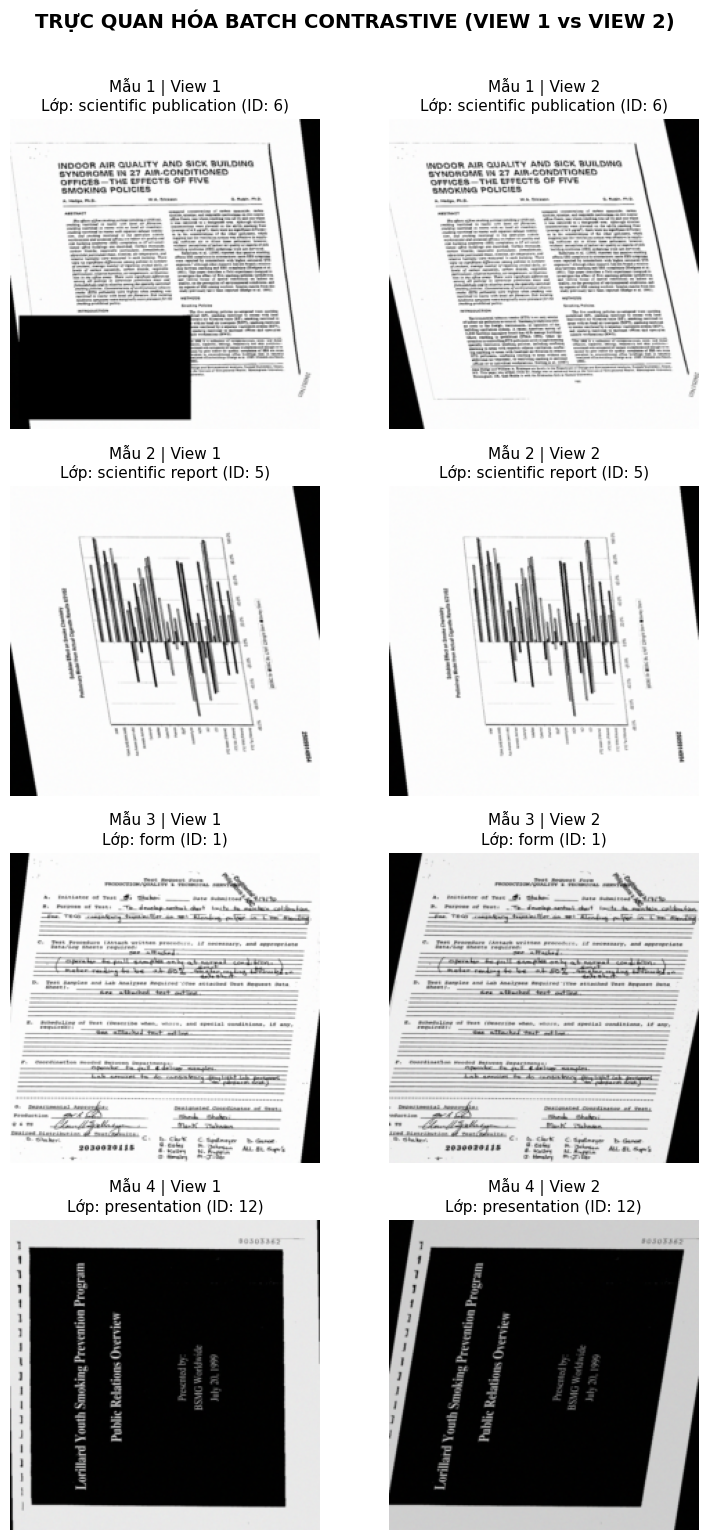

In [6]:
# 1. Tạo DataLoader
train_loader = build_dataloader(
    data_dir=data_dir,
    split="train",
    processor=processor,
    batch_size=4,
    transform=get_transforms(max_shear=10.0, noise_std=5.0, p_erase=0.3),
    is_contrastive=True,
    num_workers=0,
    max_samples=50,
)

print(f"✅ DataLoader khởi tạo thành công! Tổng số batch (max_samples=50): {len(train_loader)}")

# 2. Lấy 1 batch thực tế
batch = next(iter(train_loader))
labels = batch["labels"]
batch_size = len(labels)

print(f"Batch keys: {list(batch.keys())}")
print(f"View 1 shape: {batch['view1']['pixel_values'].shape}")
print(f"View 2 shape: {batch['view2']['pixel_values'].shape}")
print(f"Labels: {labels.tolist()} -> {[RVLCDIPDataset.LABEL_NAMES[l] for l in labels.tolist()]}")

# 3. Trực quan hóa toàn bộ batch
fig, axes = plt.subplots(batch_size, 2, figsize=(8, 3.8 * batch_size))
if batch_size == 1:
    axes = axes.reshape(1, 2)

v1_tensors = batch["view1"]["pixel_values"]
v2_tensors = batch["view2"]["pixel_values"]

for i in range(batch_size):
    label_id = labels[i].item()
    label_name = RVLCDIPDataset.LABEL_NAMES[label_id]

    # Vẽ View 1
    axes[i, 0].imshow(to_displayable(v1_tensors[i]))
    axes[i, 0].set_title(f"Mẫu {i+1} | View 1\nLớp: {label_name} (ID: {label_id})", fontsize=11)
    axes[i, 0].axis("off")

    # Vẽ View 2
    axes[i, 1].imshow(to_displayable(v2_tensors[i]))
    axes[i, 1].set_title(f"Mẫu {i+1} | View 2\nLớp: {label_name} (ID: {label_id})", fontsize=11)
    axes[i, 1].axis("off")

plt.suptitle("TRỰC QUAN HÓA BATCH CONTRASTIVE (VIEW 1 vs VIEW 2)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


## 5. Kiểm thử Khởi tạo Đồng thời 3 Split (`get_dataloaders`)
Kiểm tra hàm tiện ích `get_dataloaders` tạo cùng lúc: `train_loader`, `val_loader`, `test_loader`.


In [7]:
train_ld, val_ld, test_ld = get_dataloaders(
    data_dir=data_dir,
    processor=processor,
    batch_size=4,
    num_workers=0,
    transform=get_transforms(),
    is_contrastive=True,
    max_samples_per_split=20,
)

print("✅ Đã khởi tạo thành công 3 DataLoader:")
print(f"   - Train Loader: {len(train_ld)} batches (Contrastive = True)")
print(f"   - Val Loader  : {len(val_ld)} batches (Contrastive = False)")
print(f"   - Test Loader : {len(test_ld)} batches (Contrastive = False)")

# Kiểm tra lấy thử 1 batch từ Val Loader
val_batch = next(iter(val_ld))
print(f"Val batch keys: {list(val_batch.keys())}")
print(f"Val pixel_values shape: {val_batch['pixel_values'].shape}")
print(f"Val labels: {val_batch['labels'].tolist()}")
print("\n🎉 HOÀN THÀNH KIỂM THỬ: data_processing và dataloader hoạt động 100% chính xác!")


✅ Đã khởi tạo thành công 3 DataLoader:
   - Train Loader: 5 batches (Contrastive = True)
   - Val Loader  : 5 batches (Contrastive = False)
   - Test Loader : 5 batches (Contrastive = False)


Val batch keys: ['pixel_values', 'labels', 'image_paths']
Val pixel_values shape: torch.Size([4, 3, 224, 224])
Val labels: [11, 0, 0, 4]

🎉 HOÀN THÀNH KIỂM THỬ: data_processing và dataloader hoạt động 100% chính xác!
